<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Classify every transcript into intracellular / cell-like / high-density / noise / diffusion / other and summarise per sample.
> - **Manuscript panels:** Fig. 3C, ED Fig. 5F
> - **Inputs:** `data_with_source_score.zarr` of every dataset/segmentation
> - **Outputs:** Stacked bar plots of RNA categories
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Aim of the notebook

Combine everything from `9_other_urna_noise_proportion.ipynb` and `10_other_urna_diffusion_proportion.ipynb` into a single, exhaustive, mutually-exclusive classification of **all** RNA in each dataset into 6 categories:

1. **Intracellular**: `overlaps_cell == True`
2. **Cell-like uRNA**: `overlaps_cell == False` and `extracellular == False`
3. **High density uRNA**: `overlaps_cell == False`, `extracellular == True`, `enrichment_class == "High Density"`
4. **Noise-compatible uRNA**: the remainder (`overlaps_cell == False`, `extracellular == True`, `enrichment_class != "High Density"` - i.e. "other uRNA", same population as notebooks 9/10) whose gene is a control probe, or is not significantly above the restricted noise baseline (same Poisson model as notebook 9, refit on "other uRNA" only)
5. **Isotropic diffusion-compatible uRNA**: "other uRNA" not in (4), whose gene's spatial spread is compatible with isotropic diffusion (same precomputed Rayleigh/KS test as notebook 10)
6. **Non-technical other uRNA**: everything left in "other uRNA" - not noise, and not diffusion-compatible (including genes that couldn't be diffusion-tested)

Categories 1-3 are applied in that order (each is defined over what's left after excluding the previous ones), so "Cell-like uRNA" and "High density uRNA" never overlap even though the raw `enrichment_class == "High Density"` condition alone doesn't specify `extracellular`. Categories 4-6 partition "other uRNA" exactly as before. **A gene classified as noise-compatible (4) is treated as noise regardless of its diffusion-compatibility status** - diffusion is only evaluated for genes that already cleared the noise bar.

Every transcript falls into exactly one of the 6 categories, so the proportions for a given dataset sum to 1.0.

# Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import spatialdata as sd
import anndata as ad
from scipy.stats import poisson
from statsmodels.stats.multitest import multipletests

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


In [2]:
base_dir = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/"
saving_path = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/figures/full_rna_classification/"
os.makedirs(saving_path, exist_ok=True)

# Segmentation methods: default segmentation lives directly in `rois`,
# the other two segmentation methods each have their own root folder.
segmentations = ["rois", "rois_proseg", "rois_segger"]

# Samples to exclude from all downstream analysis/plots
excluded_samples = {"xenium_rcc", "cosmx_pancreas"}

max_p_val_noise = 0.05
max_p_val_diffusion = 0.05

category_order = [
    "Intracellular",
    "Cell-like uRNA",
    "High density uRNA",
    "Noise-compatible uRNA",
    "Isotropic diffusion-compatible uRNA",
    "Non-technical other uRNA",
]
category_colors = {
    "Intracellular": "#41bda5",
    "Cell-like uRNA": "#ed2474",
    "High density uRNA": "#9dcb3b",
    "Noise-compatible uRNA": "#e24a49",
    "Isotropic diffusion-compatible uRNA": "#3c813e",
    "Non-technical other uRNA": "#596aea",
}

# Restricted noise model (same as `9_other_urna_noise_proportion.ipynb`)

In [3]:
def compute_other_rna_noise_stats(transcripts, max_p_val_noise=0.05):
    """Fit the Poisson noise model on 'other unassigned RNA' only.

    Identical to the function of the same name in 9_other_urna_noise_proportion.ipynb
    and 10_other_urna_diffusion_proportion.ipynb.

    Returns (stats, gene_info): the aggregate stats dict, and the per-gene table
    (count, p_val_noise, is_control, fdr_noise) the stats were derived from.
    """
    n_total_transcripts = len(transcripts)

    other = transcripts.loc[
        (~transcripts["overlaps_cell"])
        & transcripts["extracellular"]
        & (transcripts["enrichment_class"] != "High Density")
    ]

    # "gene" is categorical, so value_counts() would otherwise include every
    # panel gene (count 0) even if it never occurs in this subset
    gene_counts = other["gene"].value_counts()
    gene_counts = gene_counts[gene_counts > 0]

    # control_probe is stored as real bool in some segmentation outputs (e.g. rois,
    # rois_segger) but as string[pyarrow] "True"/"False" in others (e.g. rois_proseg)
    control_probe = other["control_probe"]
    if control_probe.dtype != bool:
        control_probe = control_probe.astype(str).str.strip().str.lower().isin(["true", "1"])
    is_control_map = dict(zip(other["gene"], control_probe))

    # Noise baseline (lambda) from control probe counts within the "other RNA" subset
    control_obs = [gene_counts[g] for g in gene_counts.index if is_control_map.get(g, True)]
    lambda_noise = np.mean(control_obs) if control_obs else 1e-6

    gene_info = pd.DataFrame({"count": gene_counts})
    gene_info["p_val_noise"] = poisson.sf(gene_info["count"] - 1, lambda_noise)
    gene_info["is_control"] = gene_info.index.map(is_control_map).astype(bool)
    _, gene_info["fdr_noise"], _, _ = multipletests(gene_info["p_val_noise"], method="fdr_bh")

    real_genes = gene_info.loc[~gene_info["is_control"]]
    non_noise_genes = real_genes.index[real_genes["p_val_noise"] < max_p_val_noise]
    gene_info["is_noise_gene"] = ~gene_info.index.isin(non_noise_genes)

    if real_genes.shape[0] == 0:
        genes_noise_prop = np.nan
        urna_noise_prop = np.nan
    else:
        genes_noise_prop = 1 - len(non_noise_genes) / real_genes.shape[0]
        urna_noise_prop = 1 - other["gene"].isin(non_noise_genes).mean()

    stats = {
        "n_total_transcripts": n_total_transcripts,
        "n_other_transcripts": len(other),
        "n_other_genes": real_genes.shape[0],
        "lambda_noise": lambda_noise,
        "proportion_of_total_rna_other": (len(other) / n_total_transcripts) if n_total_transcripts else np.nan,
        "proportion_of_other_genes_noise": genes_noise_prop,
        "proportion_of_other_urna_noise": urna_noise_prop,
    }
    return stats, gene_info

# Run across all datasets: classify every transcript into the 6 categories

In [4]:
required_cols = ["gene", "overlaps_cell", "extracellular", "enrichment_class", "control_probe"]
diffusion_cols = ["ks_pval"]

records = []

for seg in segmentations:
    root_dir = os.path.join(base_dir, seg)

    for subfolder in sorted(f.path for f in os.scandir(root_dir) if f.is_dir()):
        sample = os.path.basename(subfolder)
        if sample in excluded_samples:
            continue
        zarr_path = os.path.join(subfolder, "data_with_source_score.zarr")

        if not os.path.isdir(zarr_path):
            continue

        try:
            # Points only for the transcript table - images/labels/shapes aren't needed here
            sdata = sd.read_zarr(zarr_path, selection=("points",))
            transcripts = sdata.points["transcripts"][required_cols].compute()
            # xrna_metadata is tiny (genes x metrics); reading it directly skips the much
            # larger unrelated tables (source_score, structure_table, table, ...) that
            # spatialdata's generic selection=("tables",) would otherwise pull in
            xrna_var = ad.read_zarr(os.path.join(zarr_path, "tables", "xrna_metadata")).var
        except Exception as e:
            print(f"[{seg}/{sample}] Skipped - failed to load: {e}")
            continue

        n_total = len(transcripts)
        if n_total == 0:
            print(f"[{seg}/{sample}] Skipped - no transcripts")
            continue

        # --- Categories 1-3: structural, from transcript-level columns only ---
        is_intracellular = transcripts["overlaps_cell"]
        is_cell_like = (~transcripts["overlaps_cell"]) & (~transcripts["extracellular"])
        is_high_density = (
            (~transcripts["overlaps_cell"]) & transcripts["extracellular"] & (transcripts["enrichment_class"] == "High Density")
        )
        other_mask = (
            (~transcripts["overlaps_cell"]) & transcripts["extracellular"] & (transcripts["enrichment_class"] != "High Density")
        )
        other = transcripts.loc[other_mask]

        # --- Categories 4-6: gene-level noise + diffusion classification of "other uRNA" ---
        _, gene_info = compute_other_rna_noise_stats(transcripts, max_p_val_noise=max_p_val_noise)

        available_diff_cols = [c for c in diffusion_cols if c in xrna_var.columns]
        combined = gene_info.join(xrna_var[available_diff_cols], how="left")
        if "ks_pval" in combined.columns:
            combined["diffusion_tested"] = combined["ks_pval"].notna()
            combined["is_diffusion_compatible"] = combined["diffusion_tested"] & (combined["ks_pval"] >= max_p_val_diffusion)
        else:
            combined["diffusion_tested"] = False
            combined["is_diffusion_compatible"] = False

        # Noise-compatible (control probes + genes not significantly above noise) takes
        # priority; diffusion is only decisive for genes that already cleared the noise bar
        is_cat4 = combined["is_control"] | combined["is_noise_gene"]
        is_cat5 = (~is_cat4) & combined["is_diffusion_compatible"]
        gene_category = pd.Series(6, index=combined.index)
        gene_category[is_cat5] = 5
        gene_category[is_cat4] = 4

        other_gene_cat = other["gene"].map(gene_category.to_dict())

        counts = {
            "Intracellular": int(is_intracellular.sum()),
            "Cell-like uRNA": int(is_cell_like.sum()),
            "High density uRNA": int(is_high_density.sum()),
            "Noise-compatible uRNA": int((other_gene_cat == 4).sum()),
            "Isotropic diffusion-compatible uRNA": int((other_gene_cat == 5).sum()),
            "Non-technical other uRNA": int((other_gene_cat == 6).sum()),
        }

        stats = {name: counts[name] / n_total for name in category_order}
        stats["n_total_transcripts"] = n_total
        stats["segmentation"] = seg
        stats["sample"] = sample
        records.append(stats)

        print(
            f"[{seg}/{sample}] " + ", ".join(f"{name}={stats[name]:.2f}" for name in category_order)
        )

final_classification_df = pd.DataFrame(records).set_index(["segmentation", "sample"])
final_classification_df.to_csv(os.path.join(saving_path, "full_rna_classification.csv"))
final_classification_df

[rois/atera_hsbreast] Intracellular=0.82, Cell-like uRNA=0.15, High density uRNA=0.00, Noise-compatible uRNA=0.00, Isotropic diffusion-compatible uRNA=0.00, Non-technical other uRNA=0.02


[rois/cosmx_hgsoc] Intracellular=0.73, Cell-like uRNA=0.16, High density uRNA=0.04, Noise-compatible uRNA=0.03, Isotropic diffusion-compatible uRNA=0.02, Non-technical other uRNA=0.02


[rois/cosmx_melanoma] Intracellular=0.96, Cell-like uRNA=0.03, High density uRNA=0.01, Noise-compatible uRNA=0.00, Isotropic diffusion-compatible uRNA=0.00, Non-technical other uRNA=0.00


[rois/cosmx_mousebrain] Intracellular=0.63, Cell-like uRNA=0.10, High density uRNA=0.09, Noise-compatible uRNA=0.00, Isotropic diffusion-compatible uRNA=0.00, Non-technical other uRNA=0.19


[rois/cosmx_stomach] Intracellular=0.87, Cell-like uRNA=0.07, High density uRNA=0.04, Noise-compatible uRNA=0.01, Isotropic diffusion-compatible uRNA=0.00, Non-technical other uRNA=0.00


...

[rois_segger/xenium_msbrain_5k] Intracellular=0.48, Cell-like uRNA=0.27, High density uRNA=0.04, Noise-compatible uRNA=0.00, Isotropic diffusion-compatible uRNA=0.00, Non-technical other uRNA=0.20


[rois_segger/xenium_mscolon_5k] Intracellular=0.59, Cell-like uRNA=0.34, High density uRNA=0.04, Noise-compatible uRNA=0.00, Isotropic diffusion-compatible uRNA=0.00, Non-technical other uRNA=0.03


[rois_segger/xenium_opsc_5k] Intracellular=0.65, Cell-like uRNA=0.29, High density uRNA=0.02, Noise-compatible uRNA=0.00, Isotropic diffusion-compatible uRNA=0.00, Non-technical other uRNA=0.04


[rois_segger/xenium_opsc_v1] Intracellular=0.81, Cell-like uRNA=0.16, High density uRNA=0.01, Noise-compatible uRNA=0.01, Isotropic diffusion-compatible uRNA=0.00, Non-technical other uRNA=0.00


Intracellular  Cell-like uRNA  \
segmentation sample                                              
rois         atera_hsbreast           0.821505        0.154033   
             cosmx_hgsoc              0.732534        0.156653   
             cosmx_melanoma           0.957969        0.025731   
             cosmx_mousebrain         0.626972        0.097947   
             cosmx_stomach            0.874159        0.071618   
             merscope_hsbrain         0.795925        0.197296   
             merscope_hsuterine       0.786275        0.177316   
             xenium_hsfemur           0.160644        0.516470   
             xenium_hsheart           0.158070        0.462964   
             xenium_hsprostate        0.700579        0.158324   
             xenium_hsputamen         0.185727        0.385333   
             xenium_hsskin_5k         0.782647        0.114246   
             xenium_msbrain_300       0.387105        0.320335   
             xenium_msbrain_5k        0.649000        0.109166   
             xenium_mscolon_5k        0.726493        0.227989   
             xenium_opsc_5k           0.880409        0.087003   
             xenium_opsc_v1           0.885031        0.104728   
rois_proseg  atera_hsbreast           0.789199        0.168754   
             cosmx_hgsoc              0.635964        0.223635   
             cosmx_melanoma           0.937382        0.057153   
             cosmx_mousebrain         0.626972        0.166998   
             cosmx_stomach            0.849453        0.091016   
             merscope_hsbrain         0.536224        0.316083   
             merscope_hsuterine       0.936347        0.062866   
             xenium_hsfemur           0.225521        0.463568   
             xenium_hsheart           0.232828        0.387376   
             xenium_hsprostate        0.711168        0.166769   
             xenium_hsputamen         0.295093        0.335689   
             xenium_hsskin_5k         0.732405        0.175317   
             xenium_msbrain_300       0.555745        0.258228   
             xenium_msbrain_5k        0.559472        0.249929   
             xenium_mscolon_5k        0.785456        0.148796   
             xenium_opsc_5k           0.715275        0.254835   
             xenium_opsc_v1           0.875338        0.109453   
rois_segger  atera_hsbreast           0.146638        0.613849   
             cosmx_hgsoc              0.569464        0.267912   
             cosmx_melanoma           0.951933        0.034726   
             cosmx_mousebrain         0.068803        0.487827   
             cosmx_stomach            0.830310        0.120710   
             merscope_hsbrain         0.746792        0.243799   
             merscope_hsuterine       0.877884        0.108284   
             xenium_hsfemur           0.424817        0.398145   
             xenium_hsheart           0.680942        0.280616   
             xenium_hsprostate        0.514447        0.277696   
             xenium_hsputamen         0.673996        0.197877   
             xenium_hsskin_5k         0.609796        0.257567   
             xenium_msbrain_300       0.682943        0.201770   
             xenium_msbrain_5k        0.480498        0.274816   
             xenium_mscolon_5k        0.592989        0.336561   
             xenium_opsc_5k           0.647251        0.289079   
             xenium_opsc_v1           0.809718        0.160798   

                                 High density uRNA  Noise-compatible uRNA  \
segmentation sample                                                         
rois         atera_hsbreast               0.004438               0.000154   
             cosmx_hgsoc                  0.042760               0.031312   
             cosmx_melanoma               0.014280               0.000499   
             cosmx_mousebrain             0.086380               0.000907   
             cosmx_stomach                0.040142               0.00607

## Summary tables (% of total RNA)

In [5]:
pd.set_option("display.max_rows", None)

# Per-dataset composition, as clean percentages
percent_table = (final_classification_df[category_order] * 100).round(2)
percent_table.to_csv(os.path.join(saving_path, "full_rna_classification_percent.csv"))

# Compact summary: mean composition (%) per segmentation method
summary_by_method = percent_table.groupby(level="segmentation").mean().round(2)
summary_by_method.to_csv(os.path.join(saving_path, "full_rna_classification_summary_by_method.csv"))

print("Per-dataset composition (% of total RNA):")
display(percent_table)

print("\nMean composition by segmentation method (% of total RNA):")
display(summary_by_method)

Per-dataset composition (% of total RNA):


Intracellular  Cell-like uRNA  \
segmentation sample                                              
rois         atera_hsbreast              82.15           15.40   
             cosmx_hgsoc                 73.25           15.67   
             cosmx_melanoma              95.80            2.57   
             cosmx_mousebrain            62.70            9.79   
             cosmx_stomach               87.42            7.16   
             merscope_hsbrain            79.59           19.73   
             merscope_hsuterine          78.63           17.73   
             xenium_hsfemur              16.06           51.65   
             xenium_hsheart              15.81           46.30   
             xenium_hsprostate           70.06           15.83   
             xenium_hsputamen            18.57           38.53   
             xenium_hsskin_5k            78.26           11.42   
             xenium_msbrain_300          38.71           32.03   
             xenium_msbrain_5k           64.90           10.92   
             xenium_mscolon_5k           72.65           22.80   
             xenium_opsc_5k              88.04            8.70   
             xenium_opsc_v1              88.50           10.47   
rois_proseg  atera_hsbreast              78.92           16.88   
             cosmx_hgsoc                 63.60           22.36   
             cosmx_melanoma              93.74            5.72   
             cosmx_mousebrain            62.70           16.70   
             cosmx_stomach               84.95            9.10   
             merscope_hsbrain            53.62           31.61   
             merscope_hsuterine          93.63            6.29   
             xenium_hsfemur              22.55           46.36   
             xenium_hsheart              23.28           38.74   
             xenium_hsprostate           71.12           16.68   
             xenium_hsputamen            29.51           33.57   
             xenium_hsskin_5k            73.24           17.53   
             xenium_msbrain_300          55.57           25.82   
             xenium_msbrain_5k           55.95           24.99   
             xenium_mscolon_5k           78.55           14.88   
             xenium_opsc_5k              71.53           25.48   
             xenium_opsc_v1              87.53           10.95   
rois_segger  atera_hsbreast              14.66           61.38   
             cosmx_hgsoc                 56.95           26.79   
             cosmx_melanoma              95.19            3.47   
             cosmx_mousebrain             6.88           48.78   
             cosmx_stomach               83.03           12.07   
             merscope_hsbrain            74.68           24.38   
             merscope_hsuterine          87.79           10.83   
             xenium_hsfemur              42.48           39.81   
             xenium_hsheart              68.09           28.06   
             xenium_hsprostate           51.44           27.77   
             xenium_hsputamen            67.40           19.79   
             xenium_hsskin_5k            60.98           25.76   
             xenium_msbrain_300          68.29           20.18   
             xenium_msbrain_5k           48.05           27.48   
             xenium_mscolon_5k           59.30           33.66   
             xenium_opsc_5k              64.73           28.91   
             xenium_opsc_v1              80.97           16.08   

                                 High density uRNA  Noise-compatible uRNA  \
segmentation sample                                                         
rois         atera_hsbreast                   0.44                   0.02   
             cosmx_hgsoc                      4.28                   3.13   
             cosmx_melanoma                   1.43                   0.05   
             cosmx_mousebrain                 8.64                   0.09   
             cosmx_stomach                    4.01                   0.6


Mean composition by segmentation method (% of total RNA):


,Intracellular,Cell-like uRNA,High density uRNA,Noise-compatible uRNA,Isotropic diffusion-compatible uRNA,Non-technical other uRNA
segmentation,,,,,,
rois,65.36,19.81,7.37,0.36,0.74,6.37
rois_proseg,64.71,21.39,7.42,0.45,0.57,5.46
rois_segger,60.64,26.78,5.85,0.53,0.34,5.86


# Visualization

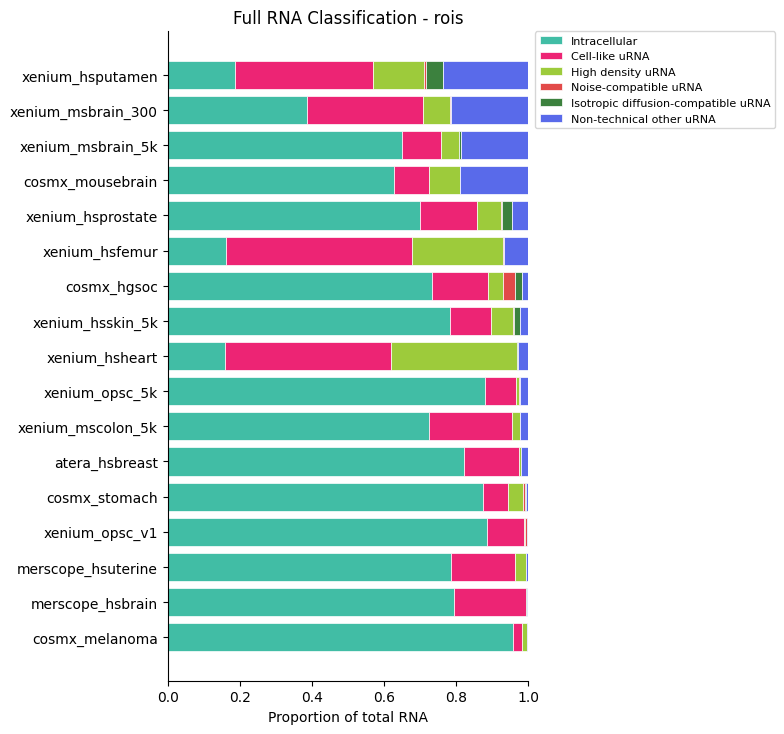

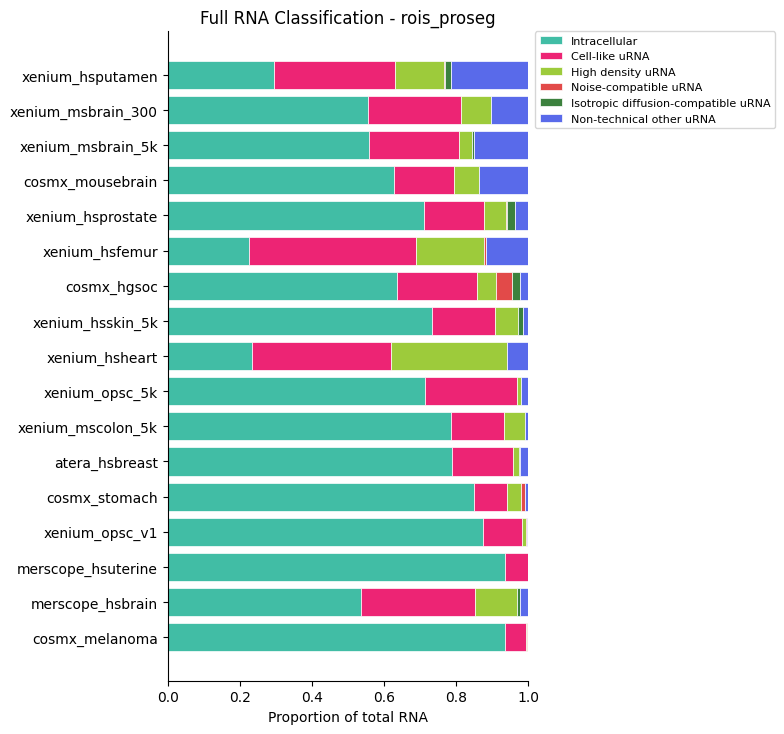

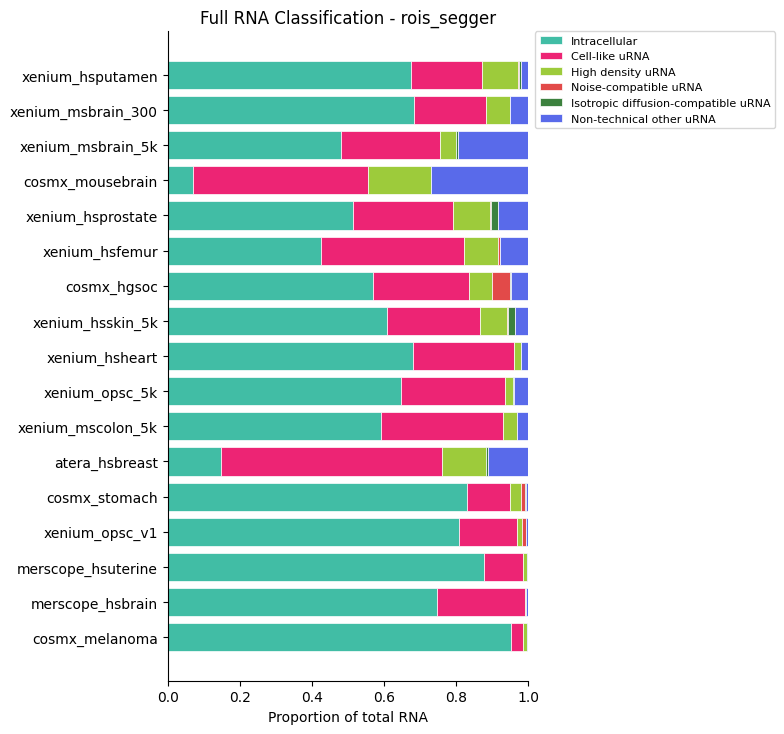

In [6]:
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Same underlying metric and sort order as 9_other_urna_noise_proportion.ipynb and
# 10_other_urna_diffusion_proportion.ipynb (mean "other uRNA" share of total RNA across
# segmentation methods, ascending), so datasets line up consistently across all 3 notebooks
other_share = (
    final_classification_df["Noise-compatible uRNA"]
    + final_classification_df["Isotropic diffusion-compatible uRNA"]
    + final_classification_df["Non-technical other uRNA"]
).rename("proportion_of_total_rna_other")

# Order samples by the default segmentation ("rois") values, so the proseg/segger
# plots line up row-for-row with the default-segmentation plot. Samples absent
# from default (present only under proseg/segger) are appended after, sorted by
# their own cross-method-averaged value.
default_order = (
    other_share.xs("rois", level="segmentation")
    .sort_values(ascending=True)
    .index.tolist()
)
remaining_order = (
    other_share.reset_index()
    .groupby("sample")["proportion_of_total_rna_other"]
    .mean()
    .sort_values(ascending=True)
    .index.tolist()
)
sample_order = default_order + [s for s in remaining_order if s not in default_order]


def plot_full_classification(df, title, out_path):
    df = df.reindex(sample_order).dropna(subset=category_order)

    fig, ax = plt.subplots(figsize=(8, 0.35 * len(df) + 1.5))
    left = np.zeros(len(df))
    for cat in category_order:
        vals = df[cat].values
        ax.barh(df.index, vals, left=left, color=category_colors[cat], edgecolor="white", linewidth=0.5, label=cat)
        left += vals

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlim(0, 1)
    ax.set_xlabel("Proportion of total RNA")
    ax.set_title(title)
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0, fontsize=8)
    plt.tight_layout()
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()


for seg in segmentations:
    if seg not in final_classification_df.index.get_level_values("segmentation"):
        continue
    df = final_classification_df.xs(seg, level="segmentation")
    plot_full_classification(
        df,
        title=f"Full RNA Classification - {seg}",
        out_path=os.path.join(saving_path, f"{seg}_barplot_full_rna_classification.pdf"),
    )